<a href="https://colab.research.google.com/github/Ansarss/Ai_learning_experiments/blob/main/Construction_Injury_Risk_RF_Bayesian_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Construction Industry Injury Risk: Random Forest + Bayesian Optimization + Bayesian Updating

 **Data:** Official U.S. OSHA Injury Tracking Application (ITA), Form 300A annual *summary* data for 2023 and 2024.  
**Population:** U.S. construction establishments (NAICS sector **23**: 236 Building Construction, 237 Heavy and Civil Engineering Construction, 238 Specialty Trade Contractors).  
**Research question:** Among construction establishments reported in both years, can **2023 characteristics and injury history** predict whether an establishment records any OSHA-reportable injury or illness in **2024**?

### Interpretation and limitations
- **Unit of analysis:** One reporting establishment (not a worker, not a construction project). Target `2024_reported_case` is **1** if OSHA Form 300A `no_injuries_illnesses == 1`; it is **0** if `no_injuries_illnesses == 2`. This is a yes/no outcome about *any* recorded injury **or illness**.
- Predictors come **only from 2023**, before the 2024 outcome period, to prevent outcome leakage.
- OSHA warns that `establishment_ID` may change if an entity is recreated. We therefore require consistent state and NAICS 3-digit subsector in matched years and report matching diagnostics; matches are not guaranteed perfect.
- This is a **covered-reporting-establishment cohort**, **not** a representative census of the U.S. construction industry. Smaller employers and nonreporters are incompletely covered.
- Historical annual rates offer **empirical priors**, not causal evidence of dangerous firms, and not medical diagnoses. No workplace safety decisions should be based solely on this model.
- **Two Bayesian methods are separate:** Optuna's TPE algorithm tunes Random Forest hyperparameters, while the Beta-Binomial model incorporates a 2023 prior and updates it using 2024 *training* outcomes. Later, optional PyMC traces validate the posterior with MCMC.

### Official references
- [OSHA ITA downloads (2023 and 2024)](https://www.osha.gov/itadata)
- [OSHA Form 300A summary data dictionary](https://www.osha.gov/sites/default/files/summary_data_dictionary.pdf)
- [OSHA ITA data user's guide](https://www.osha.gov/sites/default/files/ITA_data_users_guide.pdf)
- [Optuna TPESampler reference](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html)
- [PyMC Beta](https://www.pymc.io/projects/docs/en/stable/api/distributions/generated/pymc.Beta.html)



In [1]:
%pip -q install -U "optuna>=4,<6" "pymc>=5.20,<6" "arviz>=0.19,<0.23"

In [2]:
import io, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import scipy.stats as st
from pathlib import Path
from IPython.display import display

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss, log_loss,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay,
)
import optuna

SEED = 42
MAX_MATCHED_ROWS = 30000   # None = use every matched establishment
N_OPTUNA_TRIALS = 12       # Increase to 25+ for a deeper search
RUN_PYMC_TRACE = True      # Set False for faster execution
PRIOR_EFFECTIVE_N = 30.0  # Prior pseudo-observations per NAICS3 + 2023 size cohort
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
print('Pandas:', pd.__version__, '| Optuna:', optuna.__version__)

Pandas: 2.2.3 | Optuna: 5.1.0


## 2. Load the OSHA 2023 and 2024 establishment-level files


In [5]:
OSHA_FILES = {
  2023: 'https://www.osha.gov/sites/default/files/ITA_300A_Summary_Data_2023_through_12-31-2024.zip',
  2024: 'https://www.osha.gov/sites/default/files/ITA_300A_Summary_Data_2024_through_12-31-2025.zip',
}
DATA_MODE = 'upload'   # Change to 'upload' when automatic download is blocked

def read_annual_summary(payload: bytes, source_name: str) -> pd.DataFrame:
    """Read an OSHA ZIP (with a CSV inside) or an uncompressed CSV."""
    buffer = io.BytesIO(payload)
    if zipfile.is_zipfile(buffer):
        with zipfile.ZipFile(buffer) as archive:
            candidates = [p for p in archive.namelist() if p.lower().endswith('.csv') and not p.startswith('__MACOSX')]
            if not candidates:
                raise ValueError(f'{source_name}: no CSV inside ZIP')
            filename = max(candidates, key=lambda name: archive.getinfo(name).file_size)
            with archive.open(filename) as stream:
                df = pd.read_csv(stream, low_memory=False, encoding='utf-8-sig', encoding_errors='replace')
            print(f'{source_name} -> {filename}: {len(df):,} rows, {len(df.columns)} columns')
            return df
    df = pd.read_csv(buffer, low_memory=False, encoding='utf-8-sig', encoding_errors='replace')
    print(f'{source_name}: {len(df):,} rows, {len(df.columns)} columns')
    return df

if DATA_MODE == 'auto':
    raw = {}
    for year, url in OSHA_FILES.items():
        try:
            r = requests.get(url, headers={'User-Agent': 'Mozilla/5.0 (academic research)'}, timeout=180)
            r.raise_for_status()
            raw[year] = read_annual_summary(r.content, f'OSHA {year}')
        except Exception as exc:
            raise RuntimeError(
                f'Unable to download OSHA {year} automatically: {exc}. '
                'Download the two annual Summary Data ZIP files from https://www.osha.gov/itadata; '
                'set DATA_MODE = "upload" and rerun this cell.'
            ) from exc
elif DATA_MODE == 'upload':
    from google.colab import files
    print('Please upload exactly the 2023 and 2024 OSHA Summary Data ZIP files (or extracted CSVs).')
    uploads = files.upload()
    raw = {}
    for year in (2023, 2024):
        matching = [
    name for name in uploads
    if name.startswith(f'ITA_300A_Summary_Data_{year}_')
    and name.lower().endswith(('.csv', '.zip'))
]
        if len(matching) != 1:
            raise ValueError(f'Could not identify exactly one uploaded file for {year}. Files: {list(uploads)}')
        raw[year] = read_annual_summary(uploads[matching[0]], matching[0])
else:
    raise ValueError('DATA_MODE must be "auto" or "upload".')

for year in (2023, 2024):
    print(f'\n{year} column names:')
    print(raw[year].columns.tolist())

Please upload exactly the 2023 and 2024 OSHA Summary Data ZIP files (or extracted CSVs).


Saving ITA_300A_Summary_Data_2023_through_12-31-2024.zip to ITA_300A_Summary_Data_2023_through_12-31-2024 (1).zip
Saving ITA_300A_Summary_Data_2024_through_12-31-2025.zip to ITA_300A_Summary_Data_2024_through_12-31-2025 (1).zip
ITA_300A_Summary_Data_2023_through_12-31-2024 (1).zip -> ITA 300A Summary Data 2023 through 12-31-2024_v2.csv: 394,234 rows, 32 columns
ITA_300A_Summary_Data_2024_through_12-31-2025 (1).zip -> ITA_300A_Summary_Data_2024_through_12-31-2025_v2.csv: 398,620 rows, 32 columns

2023 column names:
['id', 'establishment_name', 'establishment_id', 'ein', 'company_name', 'street_address', 'city', 'state', 'zip_code', 'naics_code', 'naics_year', 'industry_description', 'establishment_type', 'size', 'annual_average_employees', 'total_hours_worked', 'no_injuries_illnesses', 'total_deaths', 'total_dafw_cases', 'total_djtr_cases', 'total_other_cases', 'total_dafw_days', 'total_djtr_days', 'total_injuries', 'total_skin_disorders', 'total_respiratory_conditions', 'total_poisonin

## 3. Clean, filter construction (NAICS 23), and validate the year-over-year match

OSHA Form 300A's official dictionary says `no_injuries_illnesses`: **1 = at least one recordable injury or illness; 2 = none**. We do **not** reverse this label. We use the employer's **2023** report as input and the **2024** report as the outcome.

**Data-quality safeguards:** missing IDs/invalid NAICS/invalid labels are excluded; duplicate establishment IDs are deduplicated; records must agree on state and NAICS 3-digit construction subsector. Match counts and exclusions are printed so the reader can assess selection bias.

In [6]:
def prep_year(df: pd.DataFrame, year: int) -> pd.DataFrame:
    x = df.copy()
    x.columns = [str(c).strip().lower() for c in x.columns]
    required = ['establishment_id','naics_code','state','no_injuries_illnesses',
                'size','annual_average_employees','total_hours_worked']
    missing = sorted(set(required) - set(x.columns))
    if missing:
        raise ValueError(f'{year} OSHA file is missing required columns: {missing}. Check that you uploaded Form 300A Summary Data.')

    # Convert numeric codes using nullable integers, preserving missing values.
    naics_numeric = pd.to_numeric(x['naics_code'], errors='coerce').astype('Int64')
    x['naics6'] = naics_numeric.astype(str).replace('<NA>', pd.NA).str.zfill(6)
    x = x[x['naics6'].str.fullmatch(r'23\d{4}', na=False)].copy()
    x['naics3'] = x['naics6'].str[:3]
    x['naics4'] = x['naics6'].str[:4]

    x['establishment_id'] = pd.to_numeric(x['establishment_id'], errors='coerce').astype('Int64')
    x['no_injuries_illnesses'] = pd.to_numeric(x['no_injuries_illnesses'], errors='coerce')
    x = x[x['establishment_id'].notna() & x['no_injuries_illnesses'].isin([1, 2])].copy()
    x['reported_case'] = (x['no_injuries_illnesses'] == 1).astype('int8')
    x['state'] = x['state'].astype('string').str.upper().str.strip()
    x = x[x['state'].str.fullmatch('[A-Z]{2}', na=False)].copy()

    for col in ('size','annual_average_employees','total_hours_worked',
                'total_dafw_cases','total_djtr_cases','total_other_cases'):
        if col not in x: x[col] = np.nan
        x[col] = pd.to_numeric(x[col], errors='coerce')
    x['size'] = x['size'].astype('Int64').astype(str).replace('<NA>', 'unknown')
    x.loc[x['annual_average_employees'] < 0, 'annual_average_employees'] = np.nan
    x.loc[x['total_hours_worked'] <= 0, 'total_hours_worked'] = np.nan
    x['prior_total_cases'] = x[['total_dafw_cases','total_djtr_cases','total_other_cases']].sum(axis=1, min_count=1)
    # Historical incidence rate per 100 equivalent full-time employees, not a 2024 feature.
    x['prior_tcr'] = x['prior_total_cases'] * 200000 / x['total_hours_worked']
    x['prior_tcr'] = x['prior_tcr'].replace([np.inf,-np.inf], np.nan).clip(lower=0, upper=100)
    x['cohort'] = x['naics3'] + '|' + x['size']

    if 'created_timestamp' in x.columns:
        x['_submission_sort'] = pd.to_datetime(x['created_timestamp'], errors='coerce', utc=True)
        # Some historical files store timestamps as epoch values; sort is only for deduplication.
        if x['_submission_sort'].isna().all():
            x['_submission_sort'] = x['created_timestamp'].astype(str)
        x = x.sort_values('_submission_sort', kind='stable')
    dupes = x['establishment_id'].duplicated().sum()
    x = x.drop_duplicates('establishment_id', keep='last').copy()
    print(f'{year}: {len(x):,} eligible construction establishments; {dupes:,} duplicate ID rows removed; '
          f'reported-case rate={x.reported_case.mean():.1%}')
    return x

x23 = prep_year(raw[2023], 2023)
x24 = prep_year(raw[2024], 2024)

keep23 = ['establishment_id','establishment_name','company_name','state','naics3','naics4',
          'size','annual_average_employees','total_hours_worked','reported_case',
          'prior_total_cases','prior_tcr','cohort']
for optional in ['establishment_name','company_name']:
    if optional not in x23.columns: x23[optional] = ''

joined_unchecked = x23[keep23].merge(
    x24[['establishment_id','establishment_name','state','naics3','reported_case']],
    on='establishment_id', how='inner', suffixes=('_2023','_2024'),
    validate='one_to_one'
)
match_ok = ((joined_unchecked['state_2023'] == joined_unchecked['state_2024']) &
            (joined_unchecked['naics3_2023'] == joined_unchecked['naics3_2024']))
matched = joined_unchecked[match_ok].copy()
matched = matched.rename(columns={'reported_case_2024': 'target_2024'})

print(f'\n2023 establishments found by ID in 2024: {len(joined_unchecked):,}')
print(f'Rejected due to state or NAICS3 mismatch: {(~match_ok).sum():,}')
print(f'Retained plausible historical matches: {len(matched):,}')
if 'establishment_name_2024' in matched.columns:
    clean_name = lambda s: s.fillna('').astype(str).str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
    same_name = (clean_name(matched['establishment_name_2023']) == clean_name(matched['establishment_name_2024']))
    print(f'Matched ID records with identical normalized establishment names: {same_name.mean():.1%}')
    print('Name mismatches may reflect spelling changes, business renaming, or matching problems; review them.')
print(f'2024 target prevalence within matched cohort: {matched.target_2024.mean():.2%}')
if len(matched) < 500 or matched['target_2024'].nunique() != 2:
    raise ValueError('Not enough usable 2023→2024 matched establishments for binary classification. '
                     'Review the dataset versions and ID-matching diagnostics; do not silently fall back to same-year predictors.')
if MAX_MATCHED_ROWS is not None and len(matched) > MAX_MATCHED_ROWS:
    matched = matched.sample(n=MAX_MATCHED_ROWS, random_state=SEED).reset_index(drop=True)
    print(f'Sampled {len(matched):,} matched establishments for Colab performance.')

# Remove identifying text from model input. Keep company name only to group train/test split.
display(matched[['establishment_id','state_2023','naics3_2023','size',
                 'reported_case_2023','target_2024']].head())

2023: 39,905 eligible construction establishments; 0 duplicate ID rows removed; reported-case rate=54.6%
2024: 39,137 eligible construction establishments; 0 duplicate ID rows removed; reported-case rate=52.3%

2023 establishments found by ID in 2024: 23,767
Rejected due to state or NAICS3 mismatch: 104
Retained plausible historical matches: 23,663
Matched ID records with identical normalized establishment names: 97.9%
Name mismatches may reflect spelling changes, business renaming, or matching problems; review them.
2024 target prevalence within matched cohort: 56.73%


,establishment_id,state_2023,naics3_2023,size,reported_case_2023,target_2024
0,541252,OH,238,2,0,0
1,410001,NE,238,1,0,0
2,897617,GU,236,2,1,1
3,74423,NY,238,1,0,0
4,74416,NY,238,1,1,1


## 4. Exploratory analysis (descriptive, not causal)

Check historical 2023→2024 transitions, class imbalance, and differences across the three construction subsectors. These plots describe the retained matched cohort only, not all U.S. construction employers.

Matched 2023→2024 injury/illness reporting transitions:


Reported any case 2024,0,1,All
Reported any case 2023,,,
0,6933,3090,10023
1,3307,10333,13640
All,10240,13423,23663


,2024 event share,establishments
naics3_2023,,
232,1.000000,3
236,0.480849,5091
237,0.592069,5094
238,0.590427,13475


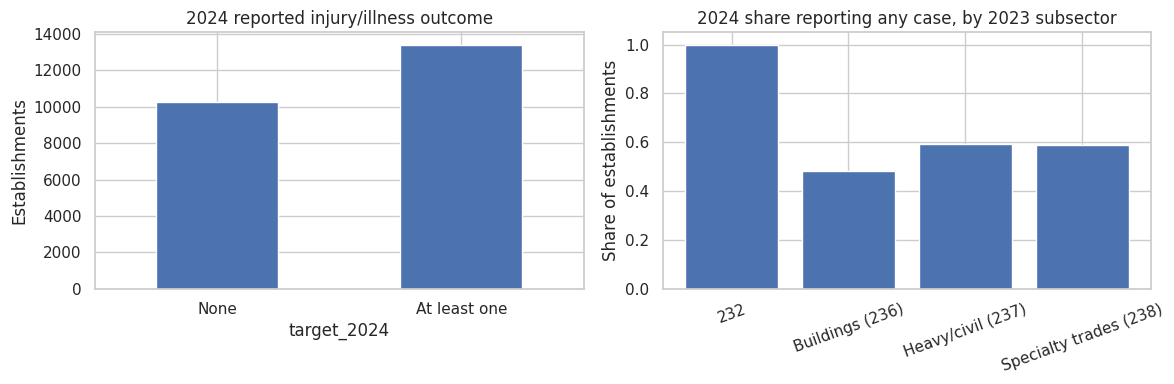

In [7]:
print('Matched 2023→2024 injury/illness reporting transitions:')
display(pd.crosstab(matched['reported_case_2023'], matched['target_2024'],
                    rownames=['Reported any case 2023'], colnames=['Reported any case 2024'], margins=True))

by_subsector = (matched.groupby('naics3_2023', observed=True)['target_2024']
                 .agg(['mean','size']).rename(columns={'mean':'2024 event share','size':'establishments'}))
display(by_subsector)
labels = {'236':'Buildings (236)', '237':'Heavy/civil (237)', '238':'Specialty trades (238)'}
fig, axs = plt.subplots(1, 2, figsize=(12,4))
matched['target_2024'].value_counts().sort_index().rename(index={0:'None',1:'At least one'}).plot.bar(ax=axs[0], title='2024 reported injury/illness outcome')
axs[0].set_ylabel('Establishments'); axs[0].tick_params(axis='x', rotation=0)
axs[1].bar([labels.get(x,x) for x in by_subsector.index], by_subsector['2024 event share'])
axs[1].set_title('2024 share reporting any case, by 2023 subsector')
axs[1].set_ylabel('Share of establishments'); axs[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

## 5. Group-aware train/test split and leakage-safe features

Use **only 2023 variables**. Names and IDs are excluded as predictors. We split by employer name (or establishment ID if missing) to reduce the risk of having the same employer in both train and test. Hyperparameter tuning is performed using group-aware cross-validation **inside the training set only**.

In [8]:
num_features = [
    'annual_average_employees', 'total_hours_worked', 'reported_case_2023',
    'prior_total_cases', 'prior_tcr'
]
cat_features = ['state_2023','naics3_2023','naics4','size']
feature_cols = num_features + cat_features

# Company grouping: approximate protection against repeat-employer leakage.
company_group = matched['company_name'].fillna('').astype(str).str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
company_group = company_group.where(company_group.str.len().ge(4), 'est_'+matched['establishment_id'].astype(str))
matched['company_group'] = company_group
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(splitter.split(matched, matched.target_2024, groups=matched.company_group))
train_df = matched.iloc[train_idx].reset_index(drop=True)
test_df = matched.iloc[test_idx].reset_index(drop=True)
X_train, y_train = train_df[feature_cols], train_df.target_2024.astype(int)
X_test, y_test = test_df[feature_cols], test_df.target_2024.astype(int)
groups_train = train_df.company_group

assert set(train_df.company_group).isdisjoint(set(test_df.company_group)), 'Company leakage in train/test split'
assert set(X_train.columns).isdisjoint(set(x24.columns) - set(x23.columns)), 'Unexpected feature name'
if y_train.nunique() != 2 or y_test.nunique() != 2:
    raise ValueError('Train/test split contains only one label. Try another SEED.')

print('Training rows:', len(train_df), 'positive class:', round(y_train.mean(),3))
print('Test rows:', len(test_df), 'positive class:', round(y_test.mean(),3))
print('Train employers:', train_df.company_group.nunique(), '| test employers:', test_df.company_group.nunique())

preprocess = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median', add_indicator=True), num_features),
    ('categorical', Pipeline([
        ('fill', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_features),
], remainder='drop')

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)

Training rows: 18763 positive class: 0.57
Test rows: 4900 positive class: 0.557
Train employers: 14281 | test employers: 3571


## 6. Baseline Random Forest

A Random Forest is a supervised ensemble of decision trees. This baseline trains on the 2024 outcomes of **training establishments** using only 2023 features. We reserve the 2024 test outcomes for final evaluation.

In [9]:
base_rf = Pipeline([
    ('features', preprocess),
    ('model', RandomForestClassifier(
        n_estimators=150, max_depth=14, min_samples_leaf=3,
        class_weight='balanced_subsample', n_jobs=-1, random_state=SEED
    ))
])
base_rf.fit(X_train, y_train)
rf_baseline_probs = base_rf.predict_proba(X_test)[:,1]
print('Baseline Random Forest fitted.')

Baseline Random Forest fitted.


## 7. Bayesian **hyperparameter optimization** with Optuna (TPE)

Optuna's Tree-structured Parzen Estimator (TPE) uses previous trial outcomes to choose promising parameter values. The objective is **3-fold group-aware ROC-AUC on the training set**. We do not optimize using the test set.

  0%|          | 0/12 [00:00<?, ?it/s]

Best cross-validated ROC-AUC: 0.8118
Chosen RF parameters: {'n_estimators': 280, 'max_depth': 15, 'min_samples_leaf': 9, 'min_samples_split': 2, 'max_features': 'sqrt'}


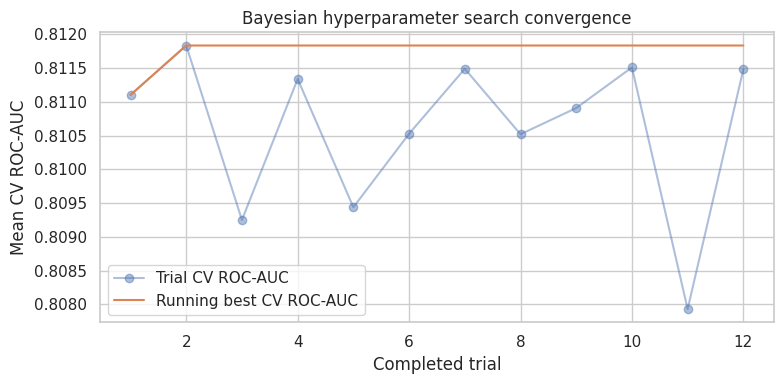

In [10]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    rf = RandomForestClassifier(
        n_estimators=trial.suggest_int('n_estimators', 80, 300, step=20),
        max_depth=trial.suggest_int('max_depth', 5, 22),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 12),
        min_samples_split=trial.suggest_int('min_samples_split', 2, 15),
        max_features=trial.suggest_categorical('max_features', ['sqrt','log2',0.7]),
        class_weight='balanced_subsample', n_jobs=-1, random_state=SEED
    )
    pipe = Pipeline([('features', preprocess), ('model', rf)])
    cv_scores = cross_val_score(pipe, X_train, y_train, groups=groups_train,
                                cv=cv, scoring='roc_auc', n_jobs=1, error_score='raise')
    return float(cv_scores.mean())

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=5))
study.optimize(objective, n_trials=N_OPTUNA_TRIALS, show_progress_bar=True)
print('Best cross-validated ROC-AUC:', round(study.best_value, 4))
print('Chosen RF parameters:', study.best_params)

# Optuna convergence: running best *training cross-validation* score, NOT test score.
trial_scores = [t.value for t in study.trials if t.value is not None]
plt.figure(figsize=(8,4))
plt.plot(range(1, len(trial_scores)+1), trial_scores, marker='o', alpha=.45, label='Trial CV ROC-AUC')
plt.plot(range(1, len(trial_scores)+1), np.maximum.accumulate(trial_scores), label='Running best CV ROC-AUC')
plt.xlabel('Completed trial'); plt.ylabel('Mean CV ROC-AUC'); plt.title('Bayesian hyperparameter search convergence')
plt.legend(); plt.tight_layout(); plt.show()

In [11]:
optimized_rf = Pipeline([
    ('features', preprocess),
    ('model', RandomForestClassifier(
        **study.best_params,
        class_weight='balanced_subsample', n_jobs=-1, random_state=SEED
    ))
])
optimized_rf.fit(X_train, y_train)
rf_optimized_probs = optimized_rf.predict_proba(X_test)[:,1]
print('Optimized Random Forest fitted.')

Optimized Random Forest fitted.


## 8. Bayesian updating: historical prior --> posterior probability

A separate Bayesian estimator uses **2023 construction-sector group event shares** as empirical prior knowledge about whether a reporting establishment records at least one injury/illness. Each group is defined by **2023 NAICS3 subsector + 2023 OSHA size category**. The update adds only **2024 training labels**. Test labels remain untouched.

For group \(g\):

\[
\theta_g \sim \mathrm{Beta}(\alpha_{0g},\beta_{0g})
\quad ;\quad S_g\mid\theta_g\sim\mathrm{Binomial}(N_g,\theta_g)
\]
\[
\theta_g\mid S_g,N_g \sim \mathrm{Beta}(\alpha_{0g}+S_g,\;\beta_{0g}+N_g-S_g)
\]

We smooth the historical 2023 group rate toward the overall 2023 construction rate, then use it as the prior center. `PRIOR_EFFECTIVE_N` controls how strongly the 2023 evidence is carried into 2024. Posterior means become **group-level** probabilities for held-out establishments. This is a **genuine probability update**, not merely a renamed Random Forest prediction.

**Critical:** Because priors are *empirically estimated* from 2023 rather than stipulated from a fully specified joint generative model, this is an **empirical-Bayes Beta-Binomial** approximation; credible intervals are conditional on estimated hyperparameters. The group model is simpler than RF and may not be more accurate.

2023 overall construction reported-case share: 54.6%
Cohorts in posterior: 19


,cohort,n23,n24_train,prior_mean,posterior_mean,ci_low,ci_high
15,238|2,8439,4600.0,0.593534,0.600387,0.586242,0.614450
16,238|21,8492,3412.0,0.550553,0.572769,0.556212,0.589247
5,236|2,4036,2182.0,0.511692,0.514622,0.493798,0.535421
10,237|2,3619,1989.0,0.613657,0.637129,0.616045,0.657956
14,238|1,2966,1051.0,0.249703,0.276076,0.249862,0.303074
6,236|21,2056,838.0,0.433956,0.437801,0.404997,0.470875
11,237|21,1865,837.0,0.482979,0.502250,0.469029,0.535461
17,238|22,1950,804.0,0.779077,0.822883,0.796303,0.848001
13,237|3,1230,703.0,0.650043,0.674560,0.640272,0.707948
18,238|3,1330,676.0,0.876719,0.884258,0.859706,0.906755


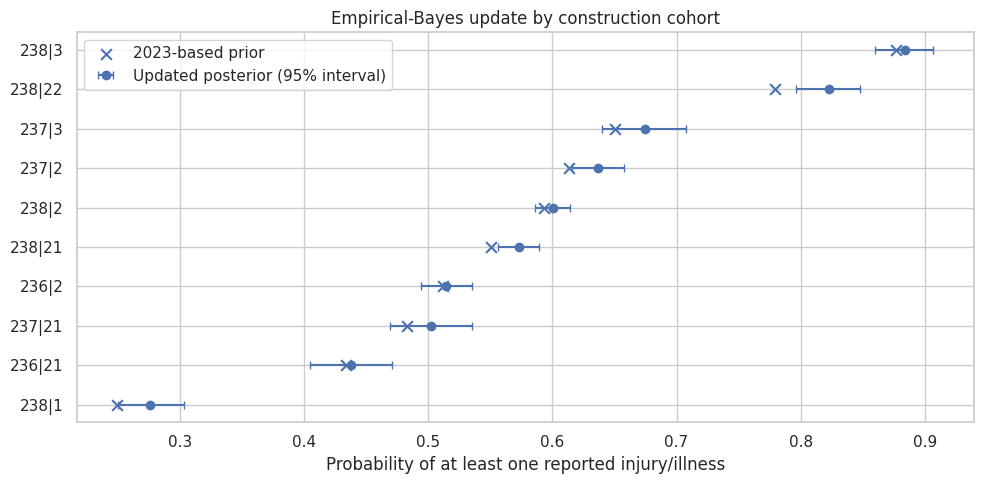

In [12]:
# Historical empirical priors from 2023 (valid for training and test firms because 2023 precedes 2024).
historical = x23[['cohort','reported_case']].copy()
global_2023_rate = historical.reported_case.mean()
h23 = historical.groupby('cohort').reported_case.agg(n23='size', s23='sum').reset_index()
SMOOTHING = 10.0
h23['historical_rate'] = (h23.s23 + SMOOTHING * global_2023_rate) / (h23.n23 + SMOOTHING)
h23['alpha0'] = 1 + PRIOR_EFFECTIVE_N * h23.historical_rate
h23['beta0'] = 1 + PRIOR_EFFECTIVE_N * (1 - h23.historical_rate)

# 2024 training outcomes are used to update priors. Never include y_test here.
train_counts = train_df.groupby('cohort').target_2024.agg(n24_train='size', s24_train='sum').reset_index()
post = h23.merge(train_counts, on='cohort', how='left')
post[['n24_train','s24_train']] = post[['n24_train','s24_train']].fillna(0)
post['alpha_post'] = post.alpha0 + post.s24_train
post['beta_post'] = post.beta0 + post.n24_train - post.s24_train
post['prior_mean'] = post.alpha0 / (post.alpha0 + post.beta0)
post['posterior_mean'] = post.alpha_post / (post.alpha_post + post.beta_post)
post['ci_low'] = st.beta.ppf(0.025, post.alpha_post, post.beta_post)
post['ci_high'] = st.beta.ppf(0.975, post.alpha_post, post.beta_post)

# Fallback for a cohort not seen in 2023: smoothed overall historical rate.
global_a0 = 1 + PRIOR_EFFECTIVE_N * global_2023_rate
global_b0 = 1 + PRIOR_EFFECTIVE_N * (1-global_2023_rate)
prior_map = post.set_index('cohort').prior_mean.to_dict()
post_map = post.set_index('cohort').posterior_mean.to_dict()
bayes_prior_probs = test_df.cohort.map(prior_map).fillna(global_a0/(global_a0+global_b0)).to_numpy()
bayes_posterior_probs = test_df.cohort.map(post_map).fillna(global_a0/(global_a0+global_b0)).to_numpy()

print('2023 overall construction reported-case share:', f'{global_2023_rate:.1%}')
print('Cohorts in posterior:', len(post))
display(post[['cohort','n23','n24_train','prior_mean','posterior_mean','ci_low','ci_high']]
        .sort_values('n24_train', ascending=False).head(12))

# Visualize how learned group probabilities move with training evidence.
plot_post = post.sort_values('n24_train',ascending=False).head(10).sort_values('posterior_mean')
fig, ax = plt.subplots(figsize=(10,5))
ypos = np.arange(len(plot_post))
ax.scatter(plot_post.prior_mean, ypos, label='2023-based prior', marker='x', s=60)
ax.errorbar(plot_post.posterior_mean, ypos,
            xerr=[plot_post.posterior_mean-plot_post.ci_low, plot_post.ci_high-plot_post.posterior_mean],
            fmt='o', capsize=3, label='Updated posterior (95% interval)')
ax.set_yticks(ypos, plot_post.cohort)
ax.set_xlabel('Probability of at least one reported injury/illness'); ax.set_title('Empirical-Bayes update by construction cohort')
ax.legend(); plt.tight_layout(); plt.show()

### Illustration: how the posterior changes as training outcomes accumulate

This is a **randomized illustrative order** of 2024 training establishments within one cohort. It is not a timestamped stream and should not be described as a real-time longitudinal updating experiment.

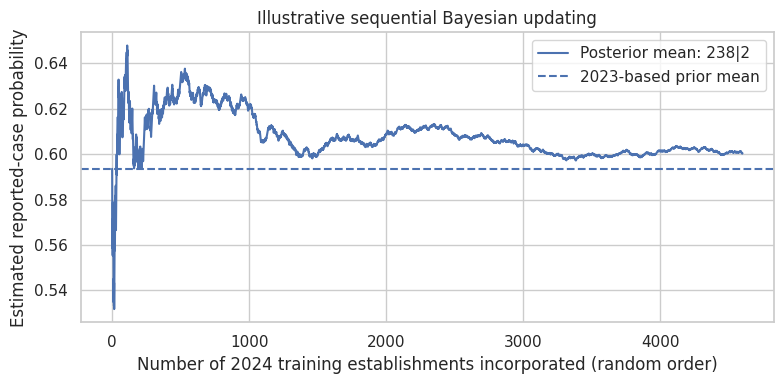

In [13]:
if len(train_counts) > 0:
    most_common = train_counts.sort_values('n24_train', ascending=False).iloc[0]['cohort']
    p = post.set_index('cohort').loc[most_common]
    events = train_df.loc[train_df.cohort.eq(most_common), 'target_2024'].to_numpy()
    events = np.random.default_rng(SEED).permutation(events)
    cumulative = np.arange(len(events)+1)
    successes = np.r_[0, events.cumsum()]
    posterior_trajectory = (p.alpha0+successes)/(p.alpha0+p.beta0+cumulative)
    plt.figure(figsize=(8,4))
    plt.plot(cumulative,posterior_trajectory, label=f'Posterior mean: {most_common}')
    plt.axhline(p.prior_mean,ls='--',label='2023-based prior mean')
    plt.xlabel('Number of 2024 training establishments incorporated (random order)')
    plt.ylabel('Estimated reported-case probability')
    plt.title('Illustrative sequential Bayesian updating')
    plt.legend();plt.tight_layout();plt.show()

## 9. Out-of-sample model comparison

Compare four predictions for the **same untouched 2024 test establishments**: (a) baseline RF, (b) RF tuned with TPE, (c) 2023 historical prior only, and (d) posterior after learning from 2024 **training** outcomes.

Metrics: Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC, Brier score, and Log Loss. A **lower** Brier score or log loss is better. The classification threshold is fixed at 0.5 for fairness; a different threshold would have to be chosen using **training** validation data, never the test data.

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier (lower better),Log Loss (lower better)
Model,,,,,,,,
Random Forest baseline,0.7233,0.7834,0.6949,0.7365,0.8055,0.8445,0.1807,0.5357
Random Forest optimized (Optuna TPE),0.7261,0.7913,0.6898,0.7371,0.8049,0.8449,0.1811,0.5369
Bayesian 2023 prior only,0.6200,0.6090,0.8860,0.7218,0.6529,0.6771,0.2272,0.6455
Bayesian 2024 posterior,0.6204,0.6052,0.9142,0.7283,0.6530,0.6770,0.2274,0.6463


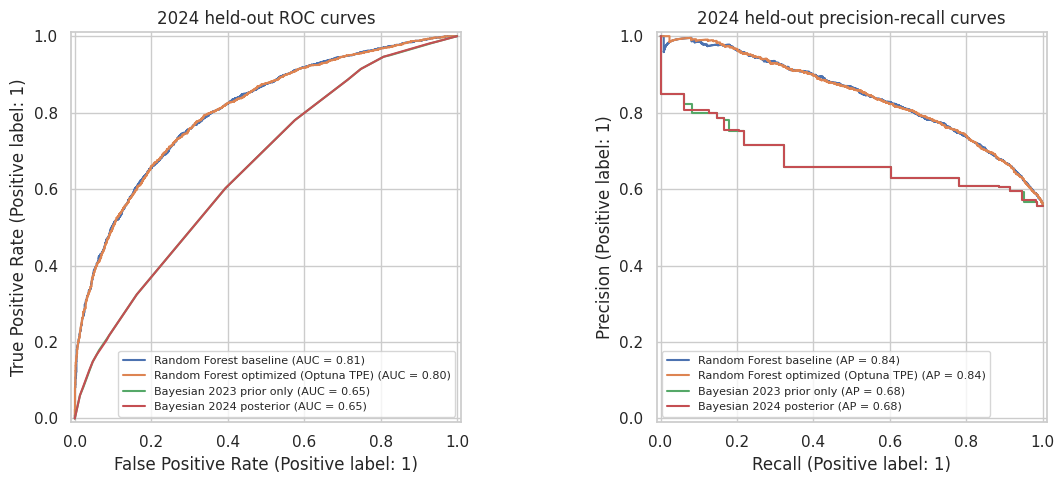

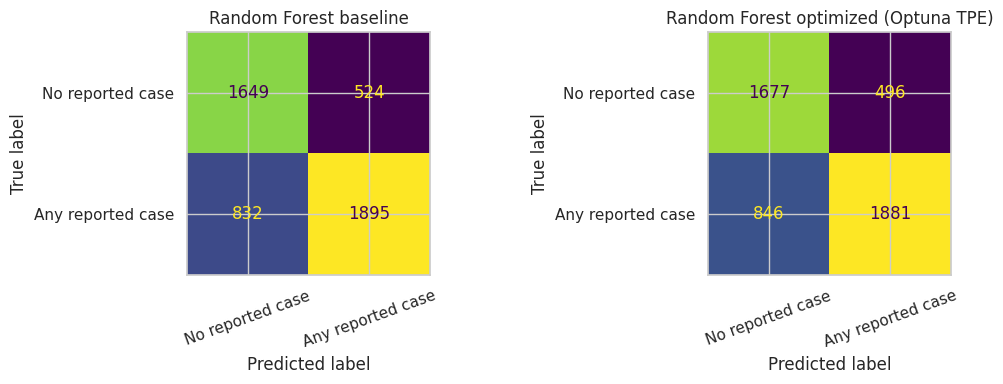

Best ROC-AUC on this single held-out test: Random Forest baseline
Reminder: higher ROC-AUC does not prove prior updating improved RF; the models are different.


In [14]:
predictions = {
    'Random Forest baseline': rf_baseline_probs,
    'Random Forest optimized (Optuna TPE)': rf_optimized_probs,
    'Bayesian 2023 prior only': bayes_prior_probs,
    'Bayesian 2024 posterior': bayes_posterior_probs,
}

def evaluate(name, probabilities):
    p = np.clip(np.asarray(probabilities, dtype=float), 1e-6, 1-1e-6)
    yhat = (p >= 0.5).astype(int)
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, yhat),
        'Precision': precision_score(y_test, yhat, zero_division=0),
        'Recall': recall_score(y_test, yhat, zero_division=0),
        'F1': f1_score(y_test, yhat, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, p),
        'PR-AUC': average_precision_score(y_test, p),
        'Brier (lower better)': brier_score_loss(y_test, p),
        'Log Loss (lower better)': log_loss(y_test, p),
    }

results = pd.DataFrame([evaluate(name,p) for name,p in predictions.items()]).set_index('Model')
display(results.round(4))

fig, (ax1,ax2) = plt.subplots(1,2,figsize=(12,5))
for name, prob in predictions.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=ax1)
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=ax2)
ax1.set_title('2024 held-out ROC curves')
ax2.set_title('2024 held-out precision-recall curves')
ax1.legend(fontsize=8); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax,(name, prob) in zip(axes, list(predictions.items())[:2]):
    ConfusionMatrixDisplay.from_predictions(y_test, (prob>=0.5).astype(int),
                                            display_labels=['No reported case','Any reported case'],
                                            ax=ax, colorbar=False)
    ax.set_title(name)
    ax.tick_params(axis='x', labelrotation=20)
plt.tight_layout(); plt.show()

best_auc = results['ROC-AUC'].idxmax()
print('Best ROC-AUC on this single held-out test:', best_auc)
print('Reminder: higher ROC-AUC does not prove prior updating improved RF; the models are different.')

## 10. Optional MCMC convergence trace with **PyMC**

Because the above Beta-Binomial model is conjugate, its posterior is available **exactly**, with no sampling needed. For the assignment's **parameter convergence plot**, we optionally reproduce the posterior of the five best-supported groups using PyMC's MCMC sampler and ArviZ trace plots. This **does not change** the test predictions, which were obtained from the exact posterior.

Check `r_hat` near 1 and effective sample size (`ess_bulk`) before trusting Monte Carlo summaries. If PyMC is unavailable or compilation is expensive, set `RUN_PYMC_TRACE = False`; the exact Bayesian updating section still works.

Output()

MCMC diagnostics (posterior risk parameters):


,mean,sd,ess_bulk,r_hat
risk[238|2],0.600,0.008,1088.0,1.0
risk[238|21],0.573,0.009,1146.0,1.0
risk[236|2],0.514,0.010,1106.0,1.0
risk[237|2],0.638,0.010,1240.0,1.0
risk[238|1],0.275,0.014,1331.0,1.0


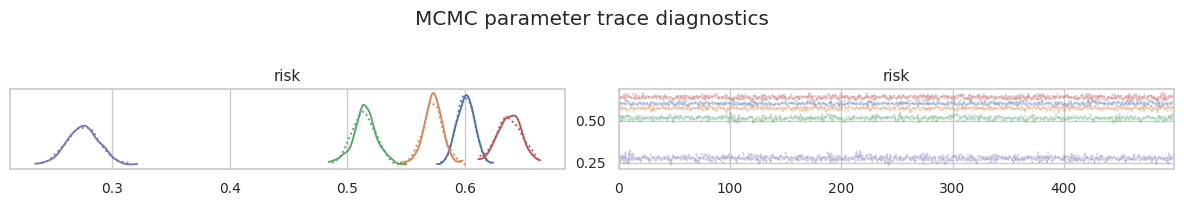

In [15]:
if RUN_PYMC_TRACE:
    import pymc as pm
    import arviz as az
    subset = post.query('n24_train >= 5').sort_values('n24_train',ascending=False).head(5).copy()
    if len(subset) == 0:
        print('No group has enough training examples for illustrative MCMC traces.')
    else:
        cohort_names = subset.cohort.tolist()
        with pm.Model(coords={'cohort': cohort_names}) as beta_binom:
            risk = pm.Beta('risk', alpha=subset.alpha0.to_numpy(dtype=float),
                           beta=subset.beta0.to_numpy(dtype=float), dims='cohort')
            cases = pm.Binomial('observed_cases', n=subset.n24_train.to_numpy(dtype=int),
                                p=risk, observed=subset.s24_train.to_numpy(dtype=int), dims='cohort')
            posterior_trace = pm.sample(draws=500, tune=500, chains=2, cores=2,
                                        random_seed=SEED, target_accept=0.9,
                                        return_inferencedata=True)
        print('MCMC diagnostics (posterior risk parameters):')
        display(az.summary(posterior_trace, var_names=['risk'])[['mean','sd','ess_bulk','r_hat']])
        az.plot_trace(posterior_trace, var_names=['risk'], compact=True)
        plt.suptitle('MCMC parameter trace diagnostics', y=1.02)
        plt.tight_layout(); plt.show()

## 11. Save reproducible outputs

Exports contain *aggregate model scores* and aggregate Bayesian cohort estimates. They do not export raw names or sensitive establishment-level files. Download via the Colab file browser or the `files.download()` option below.

In [18]:
from IPython.display import display, Markdown

# Display model performance results
display(Markdown("### Random Forest and Bayesian Model Results"))
display(results.round(6))

# Display Bayesian posterior results
display(Markdown("### Bayesian Cohort Posterior Results"))
display(
    post[
        ['cohort', 'n23', 'n24_train', 'prior_mean',
         'posterior_mean', 'ci_low', 'ci_high']
    ].round(6)
)

### Random Forest and Bayesian Model Results

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier (lower better),Log Loss (lower better)
Model,,,,,,,,
Random Forest baseline,0.723265,0.783382,0.694903,0.736494,0.805475,0.844503,0.180673,0.535696
Random Forest optimized (Optuna TPE),0.726122,0.791334,0.689769,0.737069,0.804859,0.844909,0.181085,0.536864
Bayesian 2023 prior only,0.620000,0.609024,0.885955,0.721840,0.652876,0.677112,0.227199,0.645545
Bayesian 2024 posterior,0.620408,0.605244,0.914191,0.728309,0.652977,0.676982,0.227433,0.646343


### Bayesian Cohort Posterior Results

,cohort,n23,n24_train,prior_mean,posterior_mean,ci_low,ci_high
0,232|21,1,1.0,0.581602,0.594281,0.424998,0.752733
1,232|22,2,2.0,0.613864,0.636578,0.470794,0.787140
2,232|3,1,0.0,0.581602,0.581602,0.409692,0.743843
3,235|21,1,0.0,0.496375,0.496375,0.327200,0.665979
4,236|1,1401,499.0,0.204968,0.178077,0.146744,0.211707
5,236|2,4036,2182.0,0.511692,0.514622,0.493798,0.535421
6,236|21,2056,838.0,0.433956,0.437801,0.404997,0.470875
7,236|22,439,211.0,0.650245,0.653530,0.592688,0.711978
8,236|3,486,278.0,0.814625,0.819574,0.774947,0.860298
9,237|1,954,363.0,0.258290,0.236115,0.195588,0.279172
